# Neural BHE solver

This sections presents a the implementation of a neural solver of the Backward Heat Equation (BHE) written as a BSDE and solved with a neural solver under the Deep BSDE protocol.

In [38]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

Consider the multidimensional BHE, expressed as 
\begin{equation}
    \partial_t u + \frac{1}{2} \Delta u = 0,   u(T, x) = g(x) = |x|^2, x = \xi
\end{equation}
Here $\xi$ denotes the spatial value of interest and for which the system solves. $u(T, x)$ is the terminal value and is defined by the function $g(x)$. The PDE has exact solution $u = |x|^2 + d|T-t|$.

In this implementation we consider $d = 100$, $\xi = 0$, $T=1$, $t = 0$, $N = 20$ and $\Delta t = T/N$. Note that $u(0, 0) = 100$ and $\nabla u(t, x) = 2x.

In [39]:
def heexact(t, x, T):
    # for t = 0 and x = 0 and T = 1 this will just be 'd'
    x = np.atleast_1d(x)
    d = x.shape[-1]
    return np.sum(x**2, axis=-1) + d*(T-t)

Similarly to MC the forward SDE over x can be written as $dX_t = \mu(t, X_t)dt + \sigma(t, X_t)dW_t = dW_t$ and $X_0 = \xi$
Under the Deep BSDE protocol, $u$ is represented as a stochastic process $Y_t = u(t, X_t)$ that for this equation can be derived as 
$dY_t = Z_t^TdW_t$ where $Y_T = g(X_T)$ for this particular equation. Here $Z_t$ is represented by a NN, this is the main differance from the MC method and is what makes the timestep necessary here, even though the terminal value of $x$ can be found explicitly. $Y_0$ here is also trainable and is the final value of the equation


The stochastic process can be integrated as $Y_{n +1} = Y_n + Z_n^T \Delta W_n$

In [40]:
def sample_paths(xi, bs, d, N, dt):
    """Brownian increments dW: (bs, N, d) and forward paths X: (bs, N+1, d) with X_0 = xi."""
    dW = np.sqrt(dt)*np.random.randn(bs, N, d)
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi + np.cumsum(dW, axis=1)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


def g(x):
    return (x**2).sum(-1)

Each increment in time corresponds to a part of the neural network estimating $Z_t$. These are subnets to the full NN and are represented by a module. The full net ans consequently each subnet is updated after each batch of (in this case) 64 paths are run. The paths are run forward in time and starts at $Y_0 = \theta_y$ (a trainable parameter).

Intuitivly: the parameters of $Z_t$ (with trainables $\theta_Z$) and the the learnable parameter $Y_0 = \theta_y$ are initialized more or less randomly. This allows the equation to be "solved" (i.e forward integrated in time). As paths are collected (one batch) a measure of how good the parameters are can be formulated as the difference between the value of the attained $Y_T$ and the real terminal value of $g(X_T)$. This can formulate the loss function. The value of the loss function is used to update the model weights through backpropagation and, as the model trains, the loss will shrink, effectivly solving the PDE

The loss funtion can be stated as 
\begin{equation}
    \mathcal{L}(\theta) = \frac{1}{M} \sum_{m = 1}^M |Y_N^{(m)} - g(X_N^{(m)})|^2 = \mathbb{E}[|Y_T - g(X_T)|^2]
\end{equation}

In [41]:
class SubNet(nn.Module):
    """ Subnet for each time increment Z_t, takes dimension and width as arguments.
    Typically, width = d + 10
    """
    def __init__(self, d, width):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d),
            nn.Linear(d, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, d),
        )
    def forward(self, x):
        return self.net(x)


class YZnet(nn.Module):
    def __init__(self, d, dt, N, y0_init=(0., 1.)):
            super().__init__()
            self.N, self.dt, = N, dt
            self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
            self.z0 = nn.Parameter(torch.empty(d).uniform_(-1,1))
            self.subnets = nn.ModuleList([SubNet(d, d+10) for _ in range(N-1)])
    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            t = n*self.dt
            y = y + self.dt*(z*dW[:,n]).sum(-1)
            if n < self.N-1:
                z = self.subnets[n](X[:, n + 1])
        return y


Here, the model and optimizer is set up. In this case ADAM is used, but SGD could also be used as in the original paper.

In [42]:
T = 1.0
N = 20
dt = T/N
d = 100
xi = np.zeros(d)

model = YZnet(d=d, dt=dt, N = N)
# two different learningrates for y0 and Z
opt = torch.optim.Adam([
    {"params": [model.y0], "lr": 1.0},
    {"params": [p for name, p in model.named_parameters() if name != "y0"], "lr": 1e-2},
])

The loss and train functions are defined

In [43]:
def loss_fn(model, X, dW):
    return ((model(X, dW) - g(X[:, -1]))**2).mean()

def train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose: bool = True):
    y0_hist = np.zeros(n_iter)
    loss_hist = np.zeros(n_iter)
    for i in range(n_iter):
        opt.zero_grad()

        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt )

        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        loss_hist[i] = loss
        y0_hist[i] = model.y0.item()
        
        if verbose and i % 100 == 0:
            print(f"iter {i:5d} | loss {loss_hist[i]:.4f} | Y0 {y0_hist[i]:.4f}")
    return loss_hist, y0_hist

Now the model can be trained

/var/folders/9x/q5ftyh0d39nd36l_8835rszw0000gn/T/ipykernel_51172/2334603075.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  loss_hist[i] = loss


iter     0 | loss 9523.5703 | Y0 1.9573
iter   100 | loss 644.5542 | Y0 78.8981
iter   200 | loss 164.3968 | Y0 98.6310
iter   300 | loss 165.5681 | Y0 100.1886
iter   400 | loss 226.5875 | Y0 99.5333
iter   500 | loss 216.2571 | Y0 100.0459
iter   600 | loss 223.2602 | Y0 100.3260
iter   700 | loss 244.6975 | Y0 99.4929
iter   800 | loss 175.5047 | Y0 100.1030
iter   900 | loss 196.5832 | Y0 99.9790
iter  1000 | loss 170.9248 | Y0 100.3895
iter  1100 | loss 172.0992 | Y0 100.0165
iter  1200 | loss 232.9815 | Y0 99.6398
iter  1300 | loss 165.6545 | Y0 100.5512
iter  1400 | loss 184.8189 | Y0 100.2252
iter  1500 | loss 221.0750 | Y0 100.4327
iter  1600 | loss 158.9738 | Y0 99.9193
iter  1700 | loss 208.4414 | Y0 99.5121
iter  1800 | loss 230.8861 | Y0 100.0357
iter  1900 | loss 199.8873 | Y0 99.6172
Y0 = 100.0297, exact u(0, xi) = 100.0000


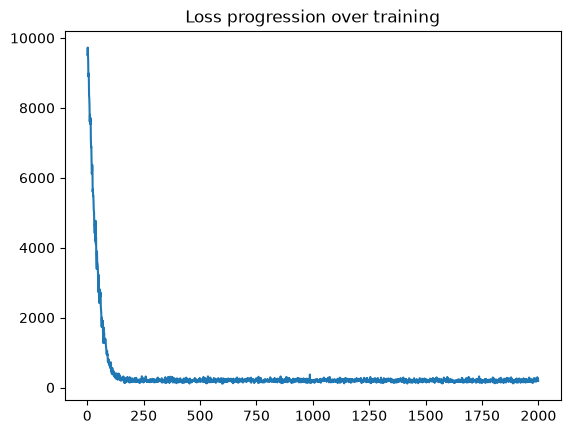

In [44]:
loss_hist, y0_hist = train(model=model, opt=opt, batch_size=64, n_iter=2000, d=d, N=N, dt=dt, xi=xi)
print(f"Y0 = {model.y0.item():.4f}, exact u(0, xi) = {heexact(0., xi, T):.4f}")

plt.plot(loss_hist)
plt.title("Loss progression over training")
plt.show()

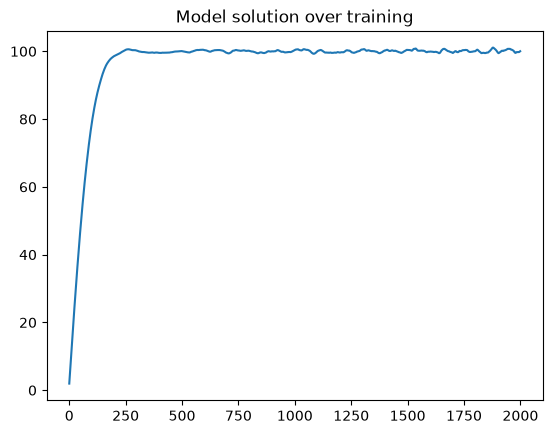

In [45]:
plt.plot(y0_hist)
plt.title("Model solution over training")
plt.show()